# Example notebook: wavelet paket transform using Energy-Kurtosis best basis selection method and k-means clustering for PCD analysis

This notebook follows the the method specified in the paper, using the results of processed synthetic signals. Here we use average energy, kurtosis, and spectral kurtosis for k-means clustering and thresholding. Energy-kurtosis best basis selection is applied to break down the signal.

In [33]:
import sys
sys.path.append("..")
if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

import scipy.ndimage as ndi
import plotly.graph_objects as go
import numpy as np

In [34]:
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.utils.preprocessing import preprocess
from wavelet_transform.utils.extensions import to_dB
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.machine_learning import fit_k_means
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.postprocess.plotting import relabel
import wavelet_transform.utils.statistical_features as sf
from wavelet_transform.utils.extensions import psd

# Import data

Copy the data file into the notebooks folder and set the filename below.

Provide the acquisition sampling rate used for the PCD measurements and the sonication frequency.

The `frequency_threshold` sets the upper frequency limit used during the analysis. Nodes with frequency content above this limit are excluded. This helps focus the clustering on the frequency band of interest. If too few DWPT nodes are retained, increase this value; if the analysis includes unnecessary high-frequency content, decrease it.

The input file may be a text file, a MATLAB `.mat` file, or any other format that can be loaded into a NumPy array. It is assumed that the data file contains two columns; 1) the first column includes the sampling times, 2) the second column includes the readings of a PCD

In [35]:
# Example 1: text file
filename = 'test_pcd_data.txt'
dataset = np.loadtxt(filename)
t_plot, data = dataset[:, 0], dataset[:, 1]

# Example 2: MATLAB .mat file
# import scipy.io as sio
# filename = 'test_pcd_data.mat'
# mat = sio.loadmat(filename)
# data = mat['data'].squeeze()  # replace 'data' with the actual variable name
# fs = 200e6  # replace with the actual sampling frequency if available
# t_plot = np.arange(len(data)) / fs  # create time vector based on sampling frequency

frequency = 1.1 * 1e6  # sonication frequency
sampling_rate = 200e6  # replace with the actual sampling frequency if available
frequency_threshold = 10e6  # adjust as described above

Calculating the energy of the original signal, to be used for post-processing later.

In [36]:
std_original = np.std(data)

### Set wavelet parameters

Parameters past this point are set as described in the paper.

In [37]:
# Bandwidth of the leaf nodes at the final level of the wavelet transform
packet_bandwidth = frequency / 2
required_levels = int(np.floor(np.log2(sampling_rate / 2 / packet_bandwidth)))
print(f"Required levels: {required_levels}")

Required levels: 7


In [38]:
# Parameters for the wavelet transform
wavelet = "sym20"  # wavelet family and order
levels = required_levels  # set to None to use max-level transform
mode = "zero"  # padding mode for dwpt: 'zero' or 'symmetric' or 'periodization'
best_basis = "energy"  # 'entropy' or 'energy' or None
min_level = 0  # minimum decomposition level
freq_threshold = min(1, frequency_threshold / (sampling_rate / 2)) # the nodes with norm_freq_range above this threshold will not be kept

threshold = 3.2  # kurtosis threshold for broadband characterisation

Three methods for adaptive decomposition are implemented, selected by setting `best_basis` parameter. They are as follows: 1. `energy`: adaptive energy_kurtosis WPT method, see the paper for details. 2. `entropy`: Standard Shannon-entropy method. 3.`none`: full symmetric decomposition. When Shannon-entropy is selected, `min_level`> 4 is required. hen full decomposition is selected, the depth is defined by setting `levels`parameter.  

# Set k-means parameters

In [39]:
# k-means parameters
kmeans_params = {
    "init": "k-means++",
    "n_init": 20,
    "max_iter": 10,
    "tol": 1e-20,
    "verbose": 0,
    "algorithm": "lloyd",
}

# Training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    "spectral kurtosis",
]

no_clusters = [2, 5]

### Preprocess data
Centering and normalising the data by its energy.

In [40]:
# Normalise data.
data_preprocessed = preprocess(data, window=False)

### DWPT

In [41]:
tr_obj = wpt.dwpt(
    data_preprocessed,
    levels,
    wavelet,
    mode,
    best_basis=best_basis,
    min_level=min_level,
    freq_threshold=freq_threshold,
)

### Check n_clusters
Check after frequency thresholding, there is sufficient nodes for clustering

In [42]:
n_nodes = len(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold))
if n_nodes < no_clusters[1]:
    print("not enough nodes. reducing number of kmeans clusters")
no_clusters[1] = min(no_clusters[1], n_nodes-1)  # set maximum number of clusters 
assert no_clusters[0] <= no_clusters[1], f"too few nodes {n_nodes}"

not enough nodes. reducing number of kmeans clusters


### Clustering

In [43]:
wpt_df_train = tr_obj.info(
    freq_threshold=freq_threshold, keep_ratio="valid", 
    metrics=classifying_metrics
)

data_train, labels, data_train_normalised, centers, scaler, kmeans = fit_k_means(
    wpt_df_train, 
    classifying_metrics,
    no_clusters=tuple(no_clusters),
    kmeans_params=kmeans_params, 
)
centers_scaled = scaler.fit_transform(centers)
relabel_metric = [metric for metric in classifying_metrics if "energy" in metric][0]
centers_sorted, labels_sorted = relabel(labels, centers, relabel_metric, ascending=False)

### Plotting

In [44]:
tr_obj.calc_frequencies(sampling_rate)

fig = plot.plotly_clustering(
    data_train, 
    centers_sorted,
    labels_sorted, 
    [classifying_metrics[i] for i in [0, 1, 2]],
    nodes=tr_obj.get_leaf_nodes(freq_threshold=freq_threshold)
)

tr_obj.plot_tree(
    node_size=20,
    node_colour=list(labels_sorted),
    freq_threshold=freq_threshold,
    show_frequency=True,
    use_plotly=True,
)

### Plotting reconstructed data

In [45]:
Font_Size = 24
Tick_Size = 24
Fig_Height = 400
Fig_Width = 800

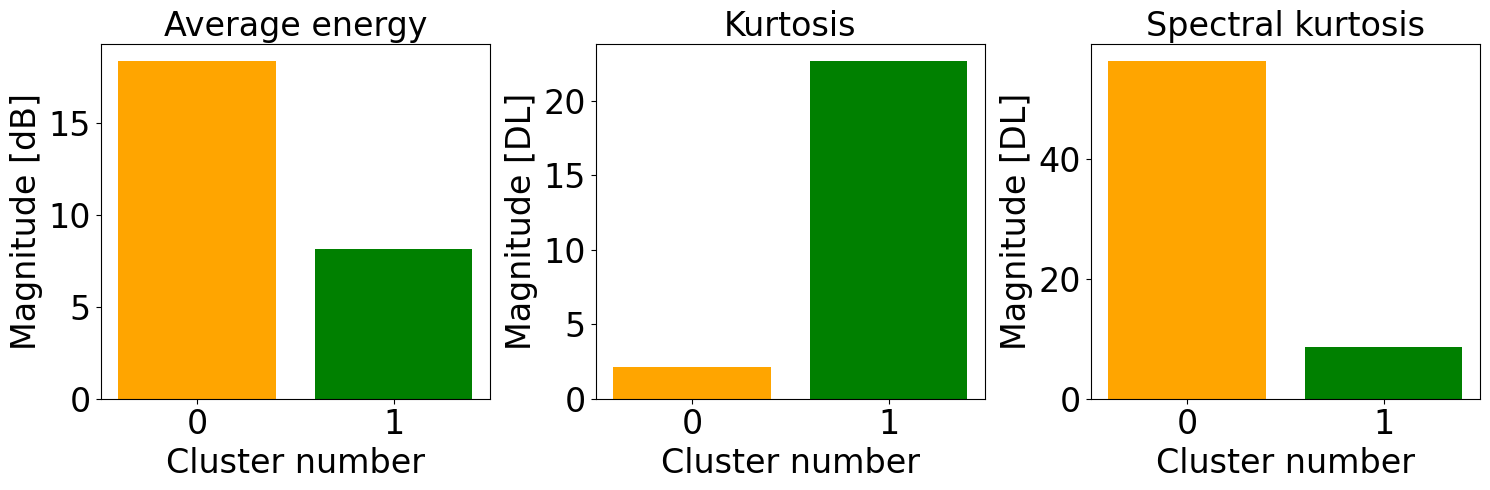

In [46]:
# In the plot_fft_by_group functin below, set clusters to None to plot all of them, otherwise, plot a list of int

fft_lim = 6  # this is the upper limit for plotting the spectrum (fft/psd of emissions)

fig = plot.plot_fft_by_group(
    tr_obj, labels_sorted, sampling_rate,
    clusters=None,
    xlims=[0,fft_lim],
    ylims=[-50,50],
    fundamental_freq=frequency,
    freq_threshold=freq_threshold,
    fig_height=Fig_Height,
    fig_width=Fig_Width,
    plot_full_reconstruction=False,
)

fig = plot.plot_reconstructions_by_group(
    tr_obj, labels_sorted, t_plot, freq_threshold,
    fig_height=Fig_Height,
    fig_width=Fig_Width,
)

fig = plot.plot_centers(
    classifying_metrics,
    centers_sorted,
)

### Rconstructing data from nodes by thresholding nodes with kurtosis threshold of 3.2
Here, as we explained in the paper, the broadband component is identified and reconstructed by multi-resolution kurtosis thresholding.  

In [47]:
def trim(data, ratio):
    lim = int((1 - ratio) / 2 * len(data))
    if lim == 0:
        return data
    return data[lim:-lim]

inv_keep_ratio = .7

# Add number to plot_centres to plot reconstructions of all nodes belonging to the cluster
# plot_centres = [i for i in range(5)]
plot_centres = np.arange(len(centers_sorted)) 
plot_centres = plot_centres[centers_sorted['kurtosis']>threshold]
reconstructions = [np.zeros(len(data_preprocessed)) for _ in range(2)]

for ii, (node, assignment) in enumerate(
    zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), labels_sorted)
):
    if int(assignment) in plot_centres:
        # List reconstructions
        rec_signal = inv.inv_node(node)

        j = 0 if sf.kurtosis(trim(rec_signal, inv_keep_ratio)) > threshold else 1  # shorten name for readability
        reconstructions[j] = reconstructions[j] + rec_signal
    else:
        rec_signal = inv.inv_node(node)
        reconstructions[1] += rec_signal


fig = go.Figure()
fig.add_trace(
    go.Scatter(
        y=reconstructions[0],
        mode="lines",
        name="higher than threshold",
    )
)
fig.add_trace(
    go.Scatter(
        y=reconstructions[1],
        mode="lines",
        name="lower than threshold",
    )
)
fig.show()


### Calculating bandwidth and energy of the broadband component of PCD signals
The broadband component is reconstructed using kurtosis thresholding carried out above. Reconstructing the time-series, we can quantify the energy, bandwidth and other statistical characteristics of the broadband component. 

In [48]:
psd_rec_higher, freq_higher = psd(reconstructions[0], sampling_rate, frequency)
psd_rec_lower, freq_lower = psd(reconstructions[1], sampling_rate, frequency)

# Generate polynomial fitting of the PSD curve
psd_curve_db = ndi.gaussian_filter1d(to_dB(psd_rec_higher), 7)
psd_curve = 10 ** (psd_curve_db / 10)

rms = np.sqrt(np.mean(psd_curve**2))
half_peak = max(psd_curve) / 2
e_peak = max(psd_curve) / np.e**2

broadband_lines = {
    "rms": rms, 
    "FWHM": half_peak, 
    "1/e<sup>2</sup> peak": e_peak
}

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=freq_higher,
        y=to_dB(psd_rec_higher),
        mode="lines",
        name="higher than threshold",
    )
)
fig.add_trace(
    go.Scatter(
        x=freq_higher,
        y=psd_curve_db,
        name="envelope"
    )
)

for line_name, line in broadband_lines.items():
    db_line = 10 * np.log10(line)
    fig.add_trace(
        go.Scatter(
            x=freq_higher,
            y=db_line*np.ones(len(freq_higher)),
            line=dict(dash="dash"),
            name=line_name
        )
    )
fig.update_layout(
    xaxis=dict(title="f / f<sub>0</sub> [DL]", range=[0, 10]),
)

fig.show()

### Energy and Kurtosis of the broadband emissions

In [49]:
print("Energy of the HIGH-kurtosis broadband [dB]: ",sf.avg_energy(trim(reconstructions[0], inv_keep_ratio))*std_original, 
      "\nEnergy of the LOW-kurtosis broadband [dB]:",sf.avg_energy(trim(reconstructions[1], inv_keep_ratio))*std_original)

Energy of the HIGH-kurtosis broadband [dB]:  1.063498460426214e-05 
Energy of the LOW-kurtosis broadband [dB]: 0.004265319839381733


In [50]:
print("Kurtosis of the HIGH-kurtosis broadband: ",sf.kurtosis(trim(reconstructions[0], inv_keep_ratio)), 
      "\nKurtosis of the LOW-kurtosis broadband:",sf.kurtosis(trim(reconstructions[1], inv_keep_ratio)))

Kurtosis of the HIGH-kurtosis broadband:  24.89965215336226 
Kurtosis of the LOW-kurtosis broadband: 1.8965185332824408


### Bandwidth of the broadband emissions
Here, we propose to quantify the bandwidth of the broadband emissions using different criteria used in optics and other acoustic applications, but not in the context of PCD analysis. These three criteria are RMS, FWHM and $1/e^2$ (which is typically used in optics). This enables us to quantify the bandwidth based on the characteristics of the reconstructed broadband compinent from PCD readings. Refer to the paper for details.

In [51]:
print("Bandwidth of the broadband component using FWHM criterion is: [{0: .2f} - {1: .2f}] x f0: ".
      format(freq_higher[psd_curve>half_peak][0], freq_higher[psd_curve>half_peak][-1]))

print("Bandwidth of the broadband component using RMS criterion is: [{0: .2f} - {1: .2f}] x f0: ".
      format(freq_higher[psd_curve>rms][0], freq_higher[psd_curve>rms][-1]))

print("Bandwidth of the broadband component using 1/e^2 criterion is: [{0: .2f} - {1: .2f}] x f0: ".
      format(freq_higher[psd_curve>e_peak][0], freq_higher[psd_curve>e_peak][-1]))
    

Bandwidth of the broadband component using FWHM criterion is: [ 2.73 -  3.83] x f0: 
Bandwidth of the broadband component using RMS criterion is: [ 2.50 -  4.97] x f0: 
Bandwidth of the broadband component using 1/e^2 criterion is: [ 2.56 -  4.58] x f0: 
